Next, you will model the sodium channel to understand the critical role of voltage alignment. The sodium channel conductance is described by an activation ($m$) and an inactivation ($h$) gate:
$$ g_{Na}(t) = \bar{g}_{Na} m(t)^3 h(t)\,. $$
The gating variables are governed by their own independent ODEs:
\begin{align}
    \tau_m(V)\frac{dm}{dt} &= m_\infty(V) - m \\
    \tau_h(V)\frac{dh}{dt} &= h_\infty(V) - h\,,
\end{align}
 where we choose steady-state functions
\begin{align*}
    m_\infty(V) &= \frac{1}{1 + e^{-(V-V_0^m)/k_m}} \\
    h_\infty(V) &= \frac{1}{1 + e^{(V-V_0^h)/k_h}}
\end{align*}
and parameters $\bar{g}_{Na} = 1.0 \text{ (mS/cm}^2\text{)}$, $V_0^m=-30.0 \text{ (mV)}$, $V_0^h=-50.0 \text{ (mV)}$, $k_m=8$, and $k_h=5$. Define the time constants as: $\tau_m(V) = 0.5$ ms and $\tau_h(V) = 5.0$ ms. Note that $\tau_m \ll \tau_h$.

In [2]:
import PyDSTool as dst
# The tool we will use for Dynamical Systems is PyDSTool https://github.com/robclewley/pydstool
import numpy as np
from matplotlib import pyplot as plt

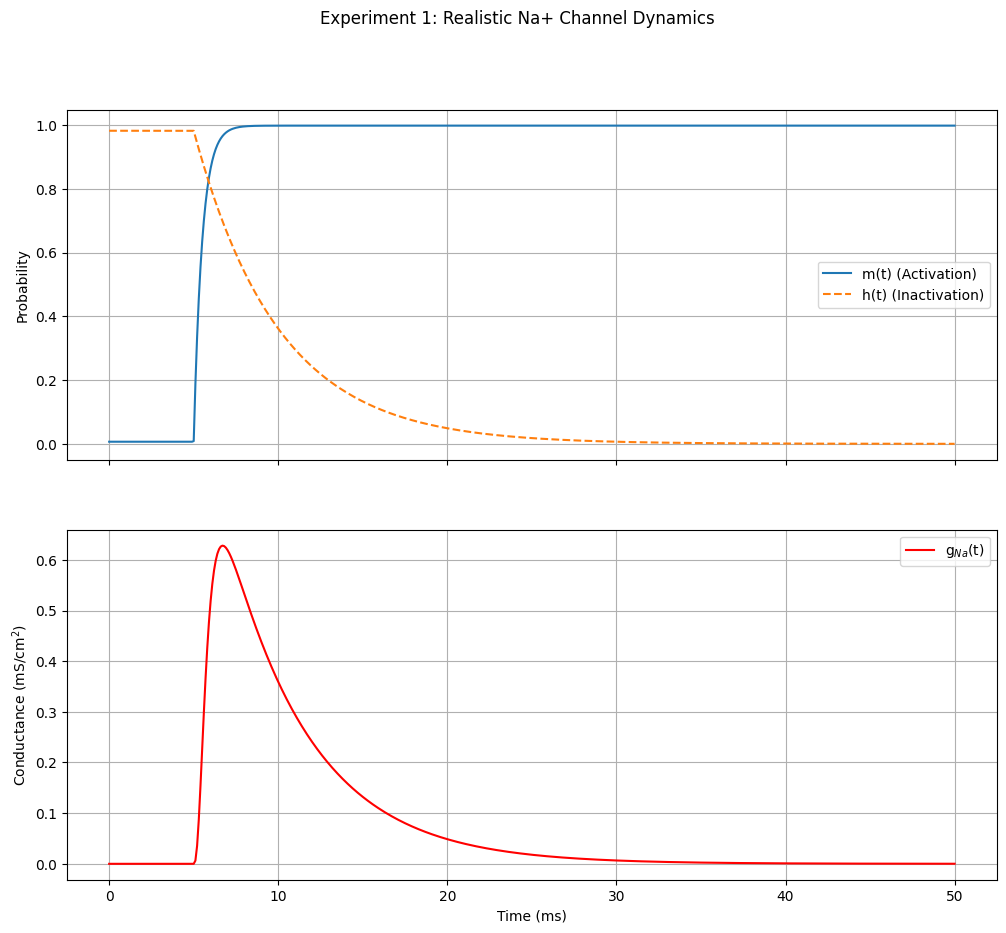

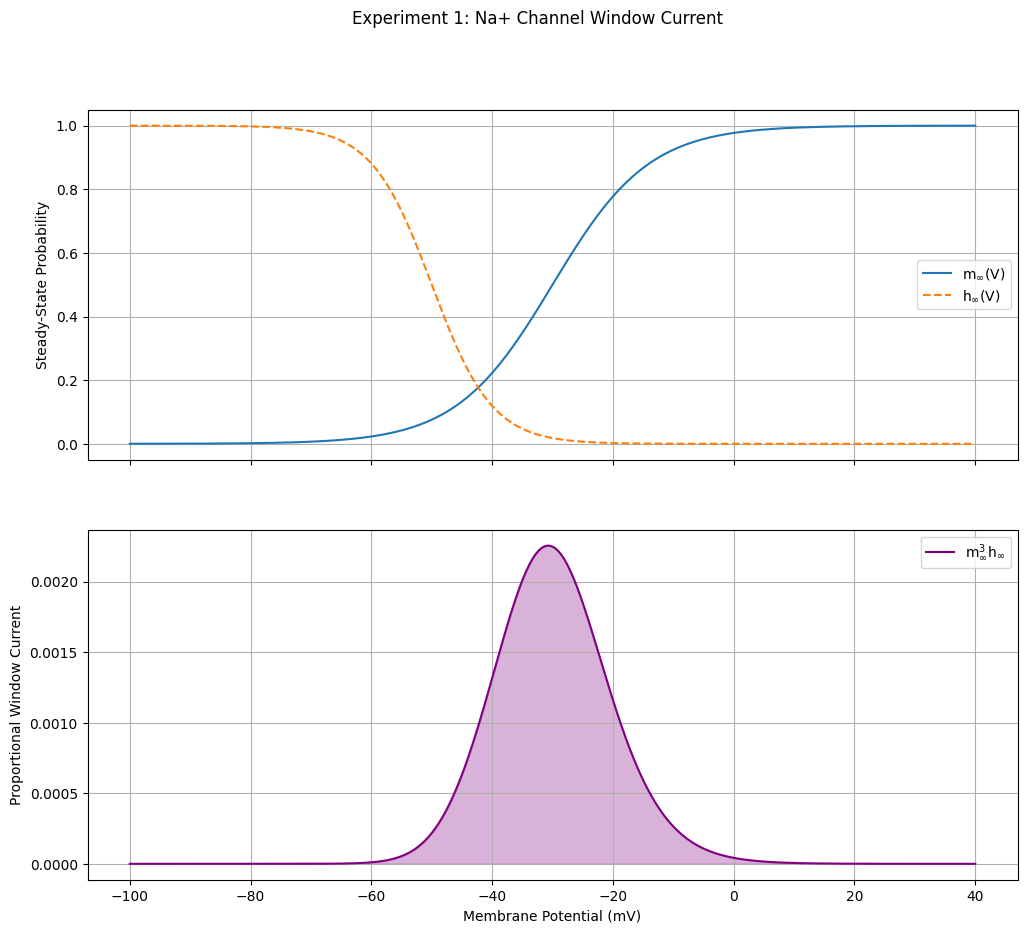

In [3]:
DSargs = dst.args(name="simple_Na_channel")

pars = {
    "g_Na_bar": 1.0,
    "V0_m": -30.0,
    "V0_h": -50.0,
    "k_m": 8.0,
    "k_h": 5.0,
    "tau_m_val": 0.5,
    "tau_h_val": 5.0,
    "V_hold": -70.0,
    "V_test": 20.0,
    "t_step": 5.0
}

fnspecs = {
    "V": (['t'], "if(t < t_step, V_hold, V_test)"),
    "m_inf": (['v'], "1 / (1 + exp(-(v - V0_m) / k_m))"),
    "h_inf": (['v'], "1 / (1 + exp((v - V0_h) / k_h))")
}

varspecs = {
    "m": "(m_inf(V(t)) - m) / tau_m_val",
    "h": "(h_inf(V(t)) - h) / tau_h_val"
}

m_initial = 1 / (1 + np.exp(-(-70.0 - -30.0) / 8.0))
h_initial = 1 / (1 + np.exp((-70.0 - -50.0) / 5.0))

ics = {
    "m": m_initial,
    "h": h_initial
}

DSargs.pars = pars
DSargs.fnspecs = fnspecs
DSargs.varspecs = varspecs
DSargs.ics = ics
DSargs.tdata = [0, 50]

ode_sys = dst.Generator.Vode_ODEsystem(DSargs)
trajectory = ode_sys.compute('Na_trajectory')
points = trajectory.sample(dt=0.1)

# Calculate conductance
g_Na_t = pars['g_Na_bar'] * (points['m']**3) * points['h']

# Plot gating and conductance
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(12, 10))
fig.suptitle('Experiment 1: Realistic Na+ Channel Dynamics')

ax1.plot(points['t'], points['m'], label='m(t) (Activation)')
ax1.plot(points['t'], points['h'], label='h(t) (Inactivation)', linestyle='--')
ax1.set_ylabel('Probability')
ax1.legend()
ax1.grid(True)

ax2.plot(points['t'], g_Na_t, color='red', label='g$_{Na}$(t)')
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Conductance (mS/cm$^2$)')
ax2.legend()
ax2.grid(True)
plt.show()

V_range = np.linspace(-100, 40, 500)

# We can reuse the Python implementations of m_inf and h_inf for the pure algebraic plot over a voltage range
m_inf_vals = 1 / (1 + np.exp(-(V_range - pars['V0_m']) / pars['k_m']))
h_inf_vals = 1 / (1 + np.exp((V_range - pars['V0_h']) / pars['k_h']))
window_current = (m_inf_vals**3) * h_inf_vals

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(12, 10))
fig.suptitle('Experiment 1: Na+ Channel Window Current')

ax1.plot(V_range, m_inf_vals, label='m$_{\infty}$(V)')
ax1.plot(V_range, h_inf_vals, label='h$_{\infty}$(V)', linestyle='--')
ax1.set_ylabel('Steady-State Probability')
ax1.legend()
ax1.grid(True)

ax2.plot(V_range, window_current, color='purple', label='m$_{\infty}^3$h$_{\infty}$')
ax2.fill_between(V_range, window_current, color='purple', alpha=0.3)
ax2.set_xlabel('Membrane Potential (mV)')
ax2.set_ylabel('Proportional Window Current')
ax2.legend()
ax2.grid(True)
plt.show()